In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

Original class share:
 satisfaction
0    0.556427
1    0.443573
Name: proportion, dtype: float64

Imbalanced class share:
 satisfaction
0    0.95
1    0.05
Name: proportion, dtype: float64


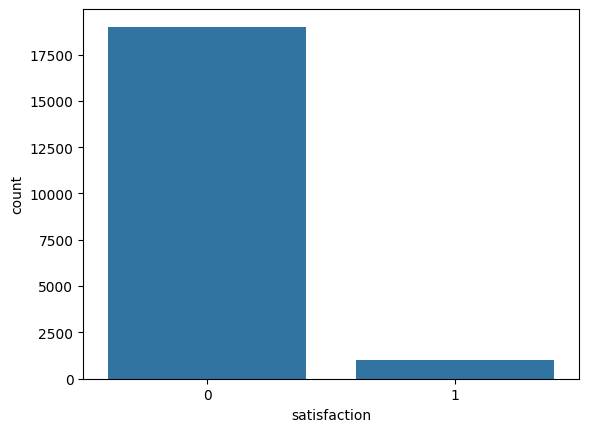

In [2]:
df = pd.read_csv('/mnt/user-data/uploads/train_2.csv')
df = df.drop(columns='id')
df['satisfaction'] = df['satisfaction'].astype(int)
print('Original class share:\n', df['satisfaction'].value_counts(normalize=True))

neg = df[df['satisfaction'] == 0].sample(19000, random_state=42)
pos = df[df['satisfaction'] == 1].sample(1000, random_state=42)
data = pd.concat([neg, pos]).sample(frac=1, random_state=42).reset_index(drop=True)

print('\nImbalanced class share:\n', data['satisfaction'].value_counts(normalize=True))
sns.countplot(x='satisfaction', data=data)
plt.show()

In [3]:
X = data.drop(columns='satisfaction')
y = data['satisfaction']

In [4]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
])

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Train positives:', y_train.sum(), '| Test positives:', y_test.sum())

Train positives: 800 | Test positives: 200


In [6]:
def evaluate(name, clf):
    pipe = Pipeline([('prep', preprocess), ('clf', clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
    }, confusion_matrix(y_test, pred)

dummy_res, dummy_cm = evaluate('Dummy (most frequent)', DummyClassifier(strategy='most_frequent'))
print(dummy_res)

{'Model': 'Dummy (most frequent)', 'Accuracy': 0.95, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0}


In [7]:
base_lr, cm_lr = evaluate('Logistic Regression (baseline)', LogisticRegression(max_iter=1000))
base_rf, cm_rf = evaluate('Random Forest (baseline)', RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1))
baseline = pd.DataFrame([dummy_res, base_lr, base_rf]).set_index('Model')
baseline.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Dummy (most frequent),0.9500,0.0000,0.000,0.0000
Logistic Regression (baseline),0.9580,0.6311,0.385,0.4783
Random Forest (baseline),0.9585,0.6133,0.460,0.5257


In [8]:
print('Accuracy alone is misleading here: a dummy model that always predicts the majority class reaches')
print(f"{dummy_res['Accuracy']:.1%} accuracy but has recall = {dummy_res['Recall']:.1f}, so it finds no satisfied passengers.")
print('Precision, recall and F1 expose how well the rare positive class is actually detected.')

Accuracy alone is misleading here: a dummy model that always predicts the majority class reaches
95.0% accuracy but has recall = 0.0, so it finds no satisfied passengers.
Precision, recall and F1 expose how well the rare positive class is actually detected.


In [9]:
bal_lr, cm_lr_b = evaluate('Logistic Regression (balanced)', LogisticRegression(max_iter=1000, class_weight='balanced'))
bal_rf, cm_rf_b = evaluate('Random Forest (balanced)', RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1))
balanced = pd.DataFrame([bal_lr, bal_rf]).set_index('Model')
balanced.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression (balanced),0.8888,0.2982,0.905,0.4486
Random Forest (balanced),0.9435,0.4654,0.875,0.6076


                                Accuracy  Precision  Recall      F1
Model                                                              
Logistic Regression (baseline)    0.9580     0.6311   0.385  0.4783
Random Forest (baseline)          0.9585     0.6133   0.460  0.5257
Logistic Regression (balanced)    0.8888     0.2982   0.905  0.4486
Random Forest (balanced)          0.9435     0.4654   0.875  0.6076


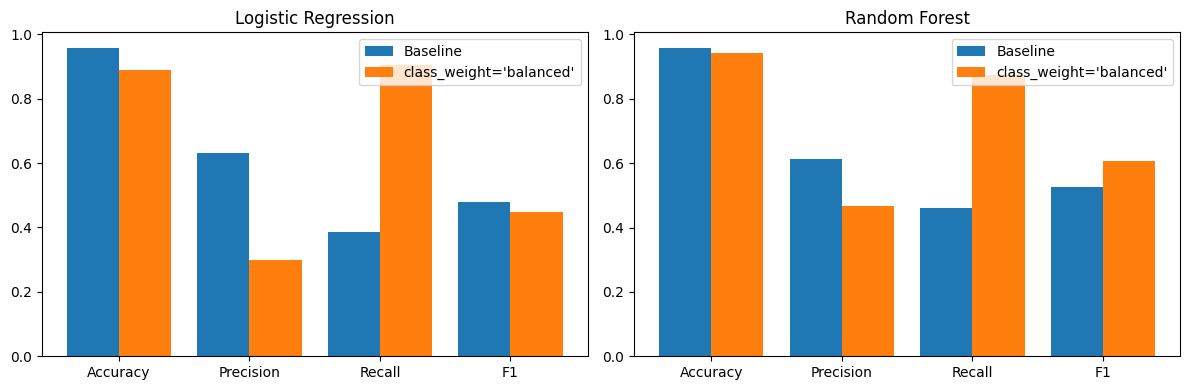

In [10]:
compare = pd.concat([baseline.loc[['Logistic Regression (baseline)', 'Random Forest (baseline)']], balanced])
print(compare.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (base, bal, title) in zip(ax, [(base_lr, bal_lr, 'Logistic Regression'), (base_rf, bal_rf, 'Random Forest')]):
    m = ['Accuracy', 'Precision', 'Recall', 'F1']
    idx = np.arange(len(m))
    a.bar(idx - 0.2, [base[k] for k in m], 0.4, label='Baseline')
    a.bar(idx + 0.2, [bal[k] for k in m], 0.4, label="class_weight='balanced'")
    a.set_xticks(idx)
    a.set_xticklabels(m)
    a.set_title(title)
    a.legend()
plt.tight_layout()
plt.show()

In [11]:
print('Confusion matrices (rows = actual, cols = predicted)')
for n, c in [('LR baseline', cm_lr), ('LR balanced', cm_lr_b), ('RF baseline', cm_rf), ('RF balanced', cm_rf_b)]:
    print(n, c.tolist())
print()
print("class_weight='balanced' penalizes mistakes on the minority class more, so recall usually rises while")
print('precision and accuracy may drop. The trade-off is acceptable when missing positives is costly;')
print('compare the F1 values above to see the net effect.')

Confusion matrices (rows = actual, cols = predicted)
LR baseline [[3755, 45], [123, 77]]
LR balanced [[3374, 426], [19, 181]]
RF baseline [[3742, 58], [108, 92]]
RF balanced [[3599, 201], [25, 175]]

class_weight='balanced' penalizes mistakes on the minority class more, so recall usually rises while
precision and accuracy may drop. The trade-off is acceptable when missing positives is costly;
compare the F1 values above to see the net effect.
